In [51]:
!pip install ultralytics
!pip install -q "huggingface_hub>=1.23.0,<2.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 17.7 MB/s eta 0:00:00


In [2]:
import kagglehub
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


# Data visualisation

In [4]:
from pathlib import Path

data = kagglehub.dataset_download("nadinpethiyagoda/vehicle-dataset-for-yolo")
DATASET_DIR = Path(data)

print("Path to dataset files:", DATASET_DIR)

Path to dataset files: /root/.cache/kagglehub/datasets/nadinpethiyagoda/vehicle-dataset-for-yolo/versions/1


In [5]:
from collections import Counter

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

images = [
    p for p in DATASET_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

labels = list(DATASET_DIR.rglob("*.txt"))

print(f"Total images: {len(images)}")
print(f"Total text annotation files: {len(labels)}")

# Count images by folder
folder_counts = Counter(
    str(p.parent.relative_to(DATASET_DIR)) for p in images
)

for folder, count in sorted(folder_counts.items()):
    print(f"{folder}: {count} images")

Total images: 3000
Total text annotation files: 3001
vehicle dataset/train/images: 2100 images
vehicle dataset/valid/images: 900 images


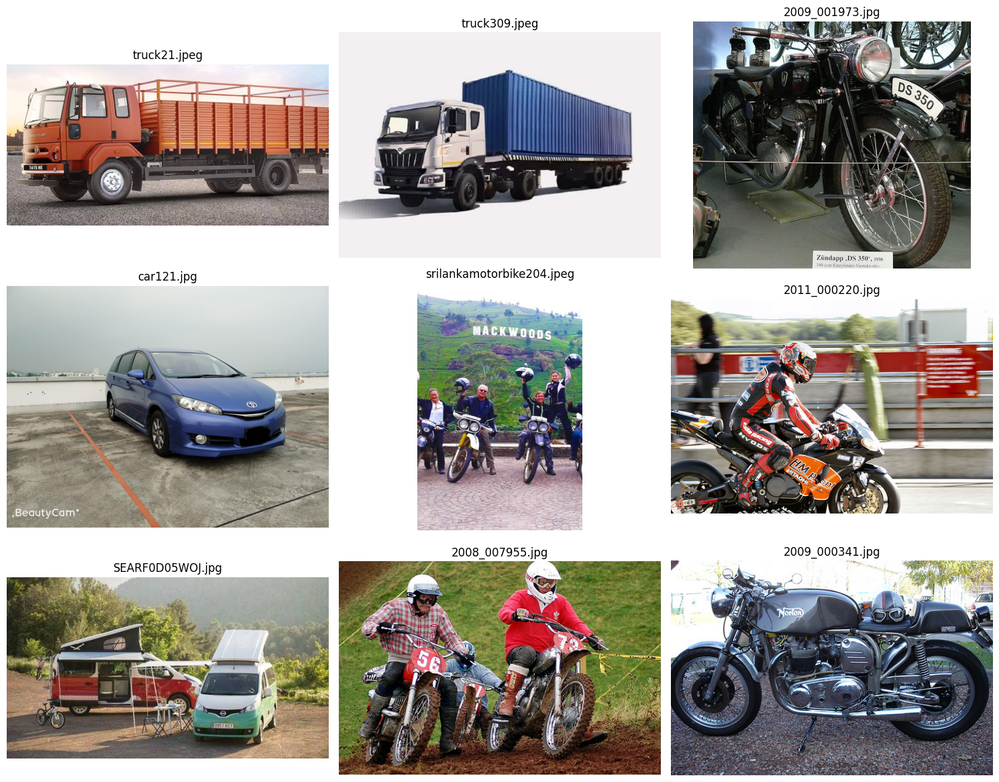

In [6]:
import matplotlib.pyplot as plt
from PIL import Image
import random

random.seed(42)

sample_size = min(9, len(images))
samples = random.sample(images, sample_size)

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for ax in axes:
    ax.axis("off")

for ax, img_path in zip(axes, samples):
    with Image.open(img_path) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(img_path.name)

plt.tight_layout()
plt.show()

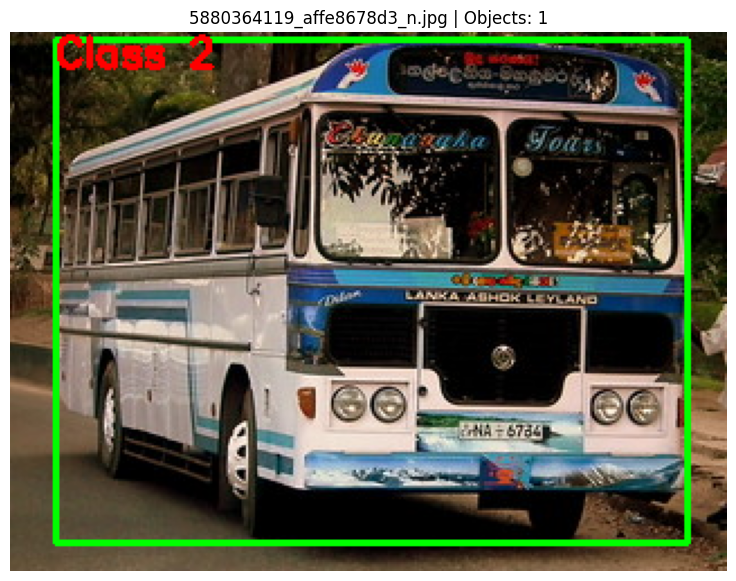

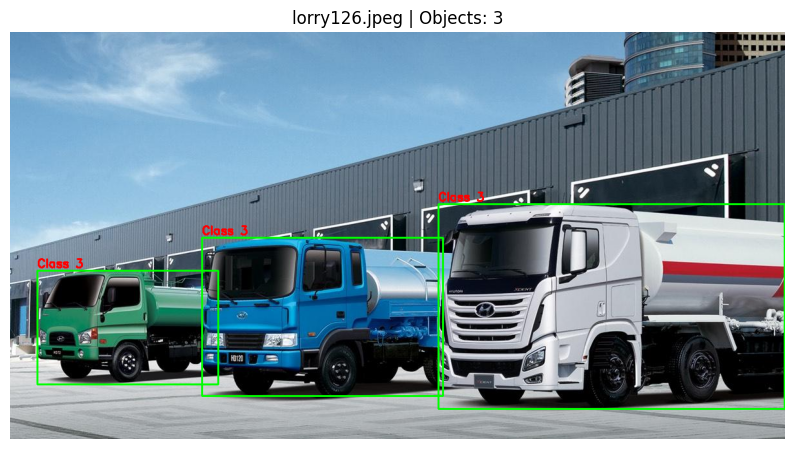

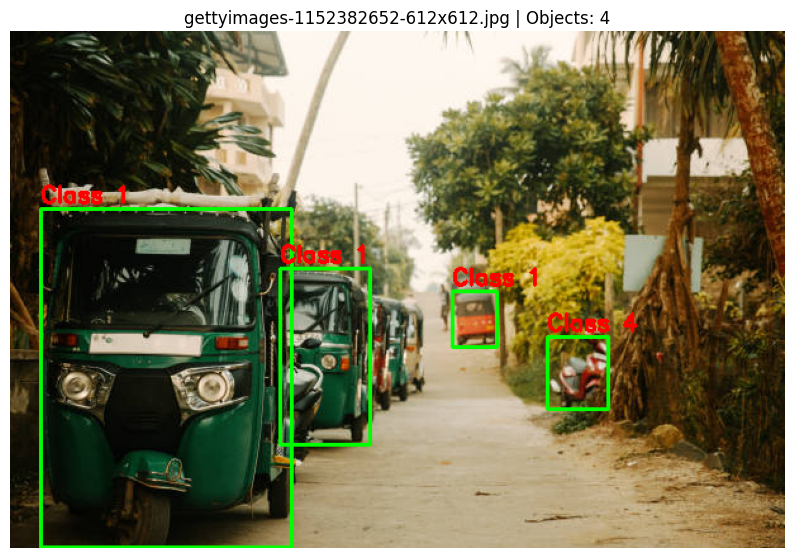

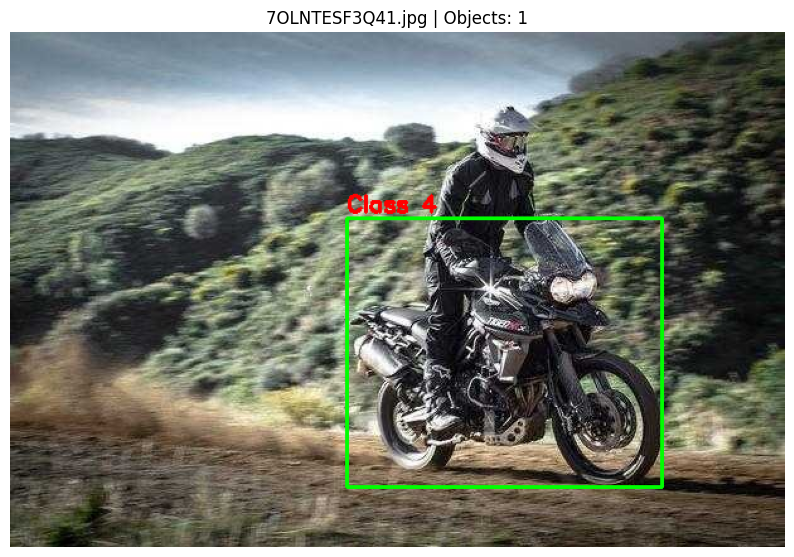

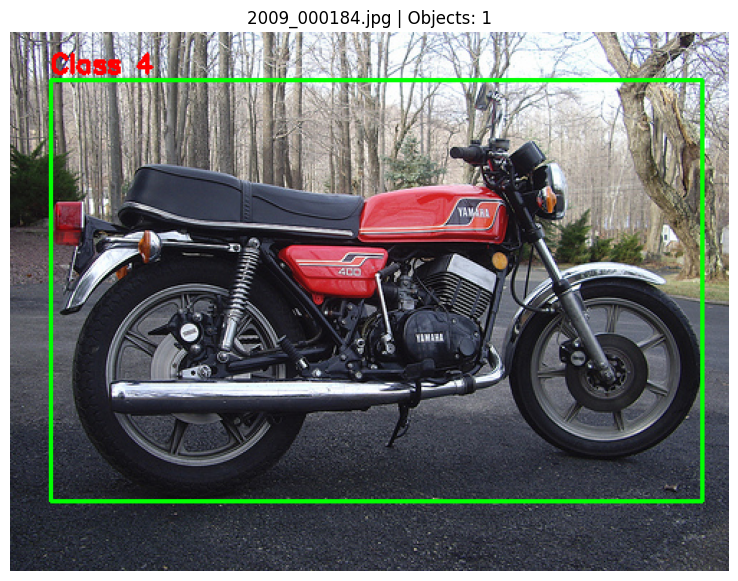

In [7]:
import cv2

def find_label_path(img_path):
    """
    First try the standard YOLO directory structure:
    images/train/image.jpg -> labels/train/image.txt

    Then fall back to searching for a matching filename.
    """
    parts = list(img_path.parts)

    if "images" in parts:
        idx = len(parts) - 1 - parts[::-1].index("images")
        label_parts = parts[:]
        label_parts[idx] = "labels"
        candidate = Path(*label_parts).with_suffix(".txt")

        if candidate.exists():
            return candidate

    candidates = list(DATASET_DIR.rglob(img_path.stem + ".txt"))
    return candidates[0] if candidates else None


def visualize_yolo_image(img_path):
    image = cv2.imread(str(img_path))

    if image is None:
        print("Could not read:", img_path)
        return

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    height, width = image.shape[:2]

    label_path = find_label_path(img_path)
    box_count = 0

    if label_path is not None:
        with open(label_path, "r") as f:
            for line in f:
                values = line.strip().split()

                if len(values) != 5:
                    continue

                class_id, xc, yc, bw, bh = map(float, values)

                x1 = int((xc - bw / 2) * width)
                y1 = int((yc - bh / 2) * height)
                x2 = int((xc + bw / 2) * width)
                y2 = int((yc + bh / 2) * height)

                x1, x2 = max(0, x1), min(width - 1, x2)
                y1, y2 = max(0, y1), min(height - 1, y2)

                cv2.rectangle(image, (x1, y1), (x2, y2),
                              (0, 255, 0), 2)

                cv2.putText(
                    image, f"Class {int(class_id)}",
                    (x1, max(y1 - 5, 15)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6,
                    (255, 0, 0), 2
                )

                box_count += 1

    plt.figure(figsize=(10, 7))
    plt.imshow(image)
    plt.title(f"{img_path.name} | Objects: {box_count}")
    plt.axis("off")
    plt.show()


for img_path in random.sample(images, min(5, len(images))):
    visualize_yolo_image(img_path)

Objects per class: {0: 662, 1: 709, 2: 588, 3: 629, 4: 699, 5: 548}
Images without label files: 0
Images with empty label files: 0


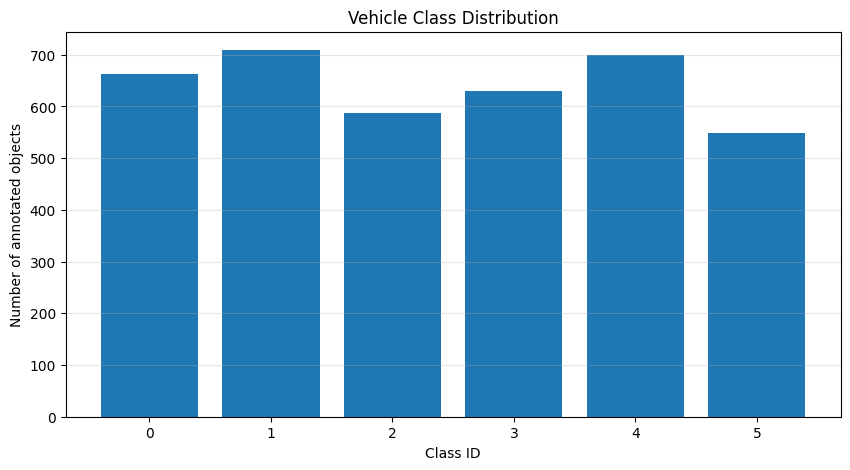

In [8]:
class_counts = Counter()
empty_labels = 0
missing_labels = 0

for img_path in images:
    label_path = find_label_path(img_path)

    if label_path is None:
        missing_labels += 1
        continue

    with open(label_path, "r") as f:
        lines = [line.strip() for line in f if line.strip()]

    if not lines:
        empty_labels += 1

    for line in lines:
        values = line.split()

        if len(values) == 5:
            try:
                class_id = int(float(values[0]))
                class_counts[class_id] += 1
            except ValueError:
                pass

print("Objects per class:", dict(sorted(class_counts.items())))
print("Images without label files:", missing_labels)
print("Images with empty label files:", empty_labels)

if class_counts:
    ids = sorted(class_counts)
    counts = [class_counts[i] for i in ids]

    plt.figure(figsize=(10, 5))
    plt.bar([str(i) for i in ids], counts)
    plt.xlabel("Class ID")
    plt.ylabel("Number of annotated objects")
    plt.title("Vehicle Class Distribution")
    plt.grid(axis="y", alpha=0.3)
    plt.show()

Corrupted or unreadable images: 0

Most common image dimensions:
320 x 240: 194 images
500 x 375: 130 images
640 x 480: 120 images
390 x 280: 117 images
500 x 333: 61 images
400 x 267: 44 images
640 x 426: 38 images
1280 x 720: 34 images
550 x 367: 33 images
600 x 450: 33 images


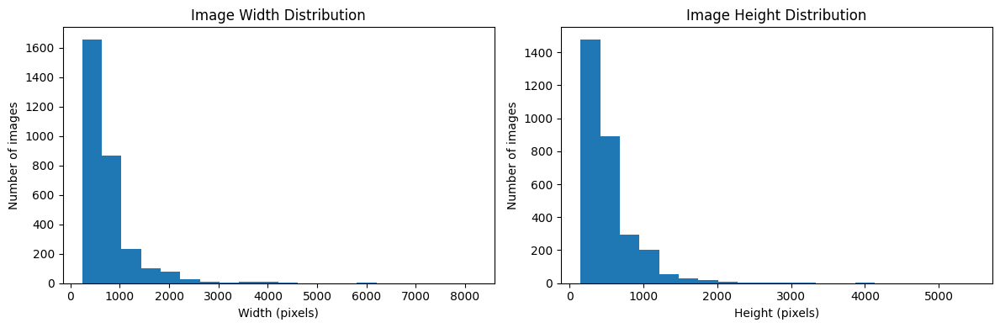

In [9]:
dimensions = []
corrupted_images = []

for img_path in images:
    try:
        with Image.open(img_path) as img:
            dimensions.append(img.size)  # (width, height)
    except Exception:
        corrupted_images.append(img_path)

print("Corrupted or unreadable images:", len(corrupted_images))

dimension_counts = Counter(dimensions)

print("\nMost common image dimensions:")
for size, count in dimension_counts.most_common(10):
    print(f"{size[0]} x {size[1]}: {count} images")

if dimensions:
    widths = [w for w, h in dimensions]
    heights = [h for w, h in dimensions]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].hist(widths, bins=20)
    axes[0].set_title("Image Width Distribution")
    axes[0].set_xlabel("Width (pixels)")
    axes[0].set_ylabel("Number of images")

    axes[1].hist(heights, bins=20)
    axes[1].set_title("Image Height Distribution")
    axes[1].set_xlabel("Height (pixels)")
    axes[1].set_ylabel("Number of images")

    plt.tight_layout()
    plt.show()

In [11]:
valid_labels = 0
invalid_labels = []
invalid_boxes = 0
total_boxes = 0

for img_path in images:
    label_path = find_label_path(img_path)

    if label_path is None:
        continue

    with open(label_path, "r") as f:
        lines = [line.strip() for line in f if line.strip()]

    file_valid = True

    for line_number, line in enumerate(lines, start=1):
        parts = line.split()

        if len(parts) != 5:
            invalid_labels.append(
                (str(label_path), line_number, "Expected 5 values")
            )
            file_valid = False
            continue

        try:
            class_value, xc, yc, bw, bh = map(float, parts)

            if (
                not all(map(lambda x: x == x and abs(x) != float("inf"),
                            [class_value, xc, yc, bw, bh]))
                or class_value < 0
                or not class_value.is_integer()
                or not (0 <= xc <= 1)
                or not (0 <= yc <= 1)
                or not (0 < bw <= 1)
                or not (0 < bh <= 1)
                or xc - bw / 2 < -1e-6
                or yc - bh / 2 < -1e-6
                or xc + bw / 2 > 1 + 1e-6
                or yc + bh / 2 > 1 + 1e-6
            ):
                invalid_boxes += 1
                invalid_labels.append(
                    (str(label_path), line_number, "Invalid box values")
                )
                file_valid = False

            total_boxes += 1

        except ValueError:
            invalid_labels.append(
                (str(label_path), line_number, "Non-numeric values")
            )
            file_valid = False

    if file_valid:
        valid_labels += 1

print("Valid label files:", valid_labels)
print("Invalid annotation lines:", len(invalid_labels))
print("Invalid bounding boxes:", invalid_boxes)
print("Total boxes inspected:", total_boxes)

for error in invalid_labels[:10]:
    print(error)

Valid label files: 3000
Invalid annotation lines: 0
Invalid bounding boxes: 0
Total boxes inspected: 3835


In [13]:
import yaml

yaml_files = list(DATASET_DIR.rglob("*.yaml")) + list(DATASET_DIR.rglob("*.yml"))

for file in yaml_files:
    print(f"\nFile: {file}")
    with open(file, "r") as f:
        config = yaml.safe_load(f)

    print("Names:", config.get("names"))
    print("Number of classes:", config.get("nc"))

In [14]:
class_counts = Counter()

for label_file in DATASET_DIR.rglob("*.txt"):
    # Skip configuration files and other unrelated text files
    if label_file.name in {"classes.txt"}:
        continue

    try:
        with open(label_file, "r") as f:
            for line in f:
                values = line.strip().split()
                if len(values) == 5:
                    class_counts[int(float(values[0]))] += 1
    except (ValueError, OSError):
        continue

for class_id, count in sorted(class_counts.items()):
    print(f"Class {class_id}: {count} objects")

Class 0: 662 objects
Class 1: 709 objects
Class 2: 588 objects
Class 3: 629 objects
Class 4: 699 objects
Class 5: 548 objects


Class ID: 0 — 3 sample images


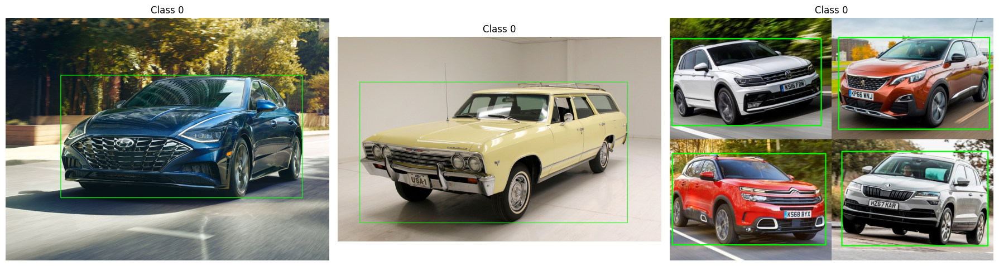

Class ID: 1 — 3 sample images


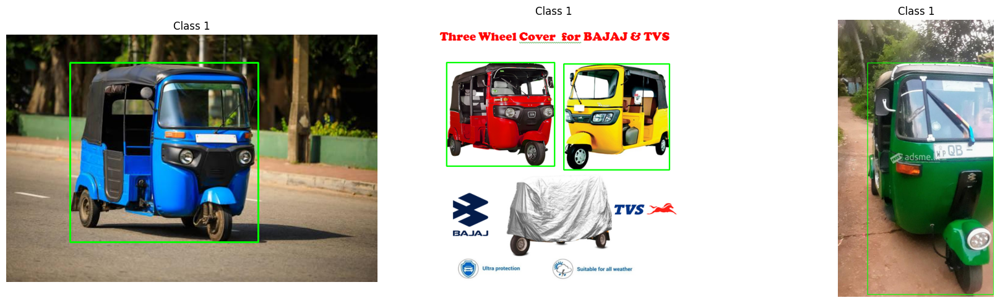

Class ID: 2 — 3 sample images


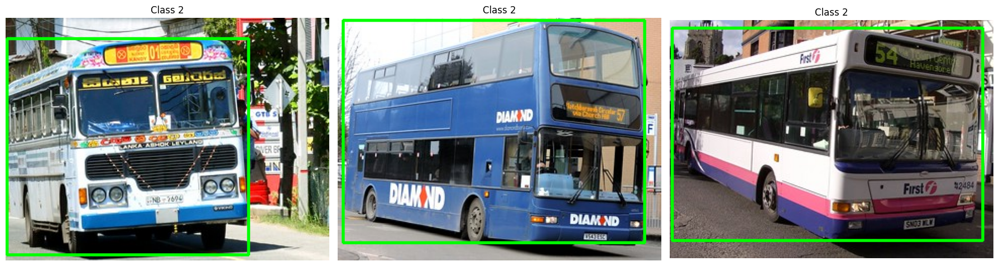

Class ID: 3 — 3 sample images


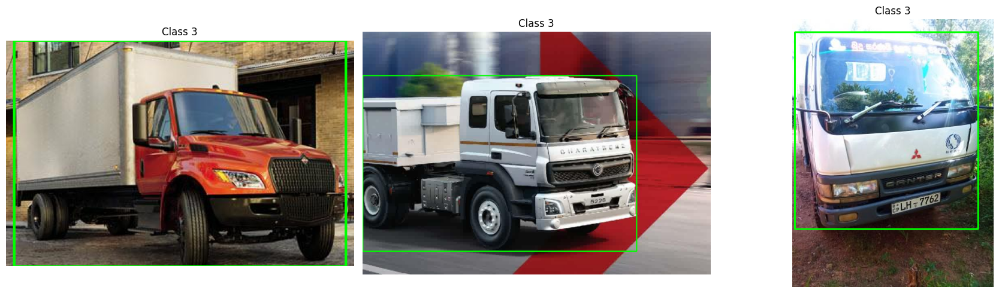

Class ID: 4 — 3 sample images


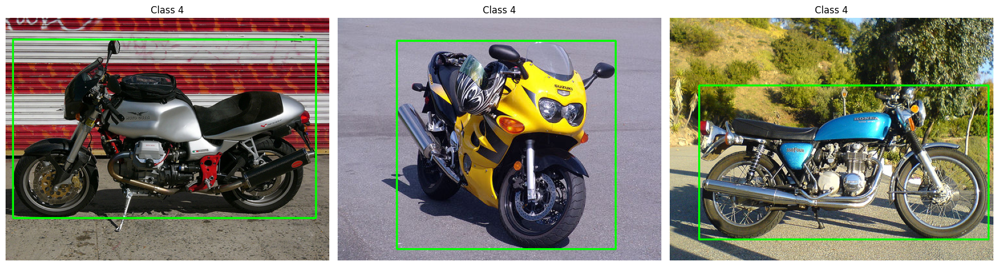

Class ID: 5 — 3 sample images


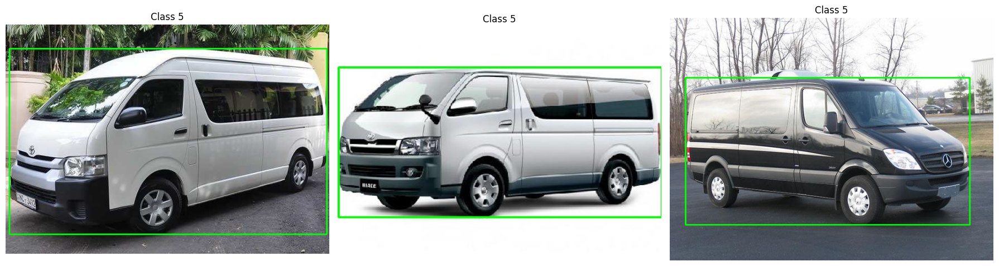

In [18]:
from collections import defaultdict

random.seed(42)

# Image extensions
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Store images and their labels for each class
class_images = defaultdict(list)

# Find YOLO label files
for label_file in DATASET_DIR.rglob("*.txt"):

    # Skip non-label text files by checking for YOLO annotation format
    try:
        lines = label_file.read_text().splitlines()
        annotations = [
            line.split() for line in lines
            if len(line.split()) == 5
        ]
    except OSError:
        continue

    if not annotations:
        continue

    # Find corresponding image
    parts = list(label_file.parts)

    if "labels" in parts:
        idx = len(parts) - 1 - parts[::-1].index("labels")
        parts[idx] = "images"
        base = Path(*parts).with_suffix("")
    else:
        base = label_file.with_suffix("")

    img_path = next(
        (base.with_suffix(ext) for ext in extensions
         if base.with_suffix(ext).is_file()),
        None
    )

    if img_path is None:
        continue

    # Record this image for every class it contains
    image_class_ids = set()

    for ann in annotations:
        try:
            image_class_ids.add(int(float(ann[0])))
        except ValueError:
            continue

    for class_id in image_class_ids:
        class_images[class_id].append((img_path, label_file))

# Display 3 images per class
for class_id in sorted(class_images):

    samples = random.sample(
        class_images[class_id],
        min(3, len(class_images[class_id]))
    )

    print(f"Class ID: {class_id} — {len(samples)} sample images")

    fig, axes = plt.subplots(1, len(samples), figsize=(6 * len(samples), 5))
    if len(samples) == 1:
        axes = [axes]

    for ax, (img_path, label_file) in zip(axes, samples):
        image = cv2.imread(str(img_path))
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        h, w = image.shape[:2]

        for line in label_file.read_text().splitlines():
            values = line.split()
            if len(values) != 5:
                continue

            try:
                cls, xc, yc, bw, bh = map(float, values)
            except ValueError:
                continue

            # Draw only boxes belonging to the current class
            if int(cls) != class_id:
                continue

            x1 = int((xc - bw / 2) * w)
            y1 = int((yc - bh / 2) * h)
            x2 = int((xc + bw / 2) * w)
            y2 = int((yc + bh / 2) * h)

            cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)

        ax.imshow(image)
        ax.set_title(f"Class {class_id}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [21]:
class_names = [
    "Car",
    "Tuk-tuk",
    "Bus",
    "Truck",
    "Motorcycle",
    "Minivan"
]

In [27]:
import shutil

valid_images = next(
    p for p in DATASET_DIR.rglob("valid/images")
    if p.is_dir()
)

dataset_root = valid_images.parent.parent
valid_labels = dataset_root / "valid" / "labels"

test_images = dataset_root / "test" / "images"
test_labels = dataset_root / "test" / "labels"

# Prevent accidentally splitting the dataset twice
if test_images.exists() and any(test_images.iterdir()):
    raise RuntimeError("Test set already contains files. No changes made.")

# Find images that have matching YOLO annotation files
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

pairs = [
    (img, valid_labels / f"{img.stem}.txt")
    for img in valid_images.iterdir()
    if img.is_file() and img.suffix.lower() in extensions
    and (valid_labels / f"{img.stem}.txt").is_file()
]

# Randomly select 50% for testing
random.seed(42)
random.shuffle(pairs)

test_pairs = pairs[:len(pairs) // 2]

# Create test directories
test_images.mkdir(parents=True, exist_ok=True)
test_labels.mkdir(parents=True, exist_ok=True)

# Move images and matching labels
for img, label in test_pairs:
    shutil.move(str(img), str(test_images / img.name))
    shutil.move(str(label), str(test_labels / label.name))

print("Dataset split completed!")
print("Train images:", len(list((dataset_root / "train/images").glob("*"))))
print("Validation images:", len(list(valid_images.glob("*"))))
print("Test images:", len(list(test_images.glob("*"))))
print("Test labels:", len(list(test_labels.glob("*.txt"))))

Dataset split completed!
Train images: 2100
Validation images: 450
Test images: 450
Test labels: 450


# Training Model

In [35]:
DATASET_DIR = Path(
    "/root/.cache/kagglehub/datasets/nadinpethiyagoda/"
    "vehicle-dataset-for-yolo/versions/1/vehicle dataset"
)

In [36]:
data_config = {
    "path": str(DATASET_DIR),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "names": dict(enumerate(class_names))
}

yaml_path = DATASET_DIR / "vehicle.yaml"

with open(yaml_path, "w") as f:
    yaml.safe_dump(data_config, f, sort_keys=False)

print("YAML updated:", yaml_path)
print("Train images exist:", (DATASET_DIR / "train/images").exists())
print("Validation images exist:", (DATASET_DIR / "valid/images").exists())
print("Test images exist:", (DATASET_DIR / "test/images").exists())

YAML updated: /root/.cache/kagglehub/datasets/nadinpethiyagoda/vehicle-dataset-for-yolo/versions/1/vehicle dataset/vehicle.yaml
Train images exist: True
Validation images exist: True
Test images exist: True


In [38]:
# Load YOLO26
model = YOLO("yolo26n.pt")

In [39]:
# Train the model on the Carparts Segmentation dataset
train_results = model.train(
    data=str(yaml_path),
    epochs=50,
    imgsz=640,
    batch=16,
    patience=10,
    plots=True

    )

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/root/.cache/kagglehub/datasets/nadinpethiyagoda/vehicle-dataset-for-yolo/versions/1/vehicle dataset/vehicle.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0

In [44]:

best_path = Path(train_results.save_dir) / "weights" / "best.pt"
print(best_path.resolve())

/content/runs/detect/train/weights/best.pt


In [43]:
best_model = YOLO("runs/detect/train/weights/best.pt")

In [45]:
val_results = best_model.val(
    data=str(yaml_path),
    split="val",
    imgsz=640
)

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,950 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2619.1±1190.0 MB/s, size: 94.0 KB)
val: Scanning /root/.cache/kagglehub/datasets/nadinpethiyagoda/vehicle-dataset-for-yolo/versions/1/vehicle dataset/valid/labels.cache... 450 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 450/450 67.4Mit/s 0.0s
val: /root/.cache/kagglehub/datasets/nadinpethiyagoda/vehicle-dataset-for-yolo/versions/1/vehicle dataset/valid/images/car55.jpg: corrupt JPEG restored and saved
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 29/29 5.2it/s 5.6s
                   all        450        579      0.961      0.962      0.978      0.918
                   Car         95        108      0.925      0.917      0.959      0.915
               Tuk-tuk         74         95      0.968      0.95

# Model evaluation

In [46]:
test_results = best_model.val(
    data=str(yaml_path),
    split="test",
    imgsz=640
)

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,950 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2036.5±511.8 MB/s, size: 65.9 KB)
val: Scanning /root/.cache/kagglehub/datasets/nadinpethiyagoda/vehicle-dataset-for-yolo/versions/1/vehicle dataset/test/labels.cache... 450 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 450/450 145.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 29/29 5.2it/s 5.6s
                   all        450        571      0.976      0.953      0.988      0.925
                   Car         87         93      0.945      0.989      0.991      0.969
               Tuk-tuk         93        132          1      0.927      0.994      0.924
                   Bus         77         90      0.994      0.989      0.994      0.958
                 Truck         63         75      

In [47]:
def show_metrics(name, results):
    print(f"\n--- {name} Metrics ---")
    print(f"Precision: {results.box.mp:.4f}")
    print(f"Recall:    {results.box.mr:.4f}")
    print(f"mAP50:     {results.box.map50:.4f}")
    print(f"mAP50-95:  {results.box.map:.4f}")

show_metrics("Validation", val_results)
show_metrics("Test", test_results)


--- Validation Metrics ---
Precision: 0.9606
Recall:    0.9616
mAP50:     0.9784
mAP50-95:  0.9182

--- Test Metrics ---
Precision: 0.9760
Recall:    0.9531
mAP50:     0.9878
mAP50-95:  0.9246



image 1/1 /root/.cache/kagglehub/datasets/nadinpethiyagoda/vehicle-dataset-for-yolo/versions/1/vehicle dataset/street-traffic.webp: 640x448 16 Cars, 24 Trucks, 1 Minivan, 14.3ms
Speed: 2.0ms preprocess, 14.3ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 448)
Results saved to /content/runs/detect/predict-2


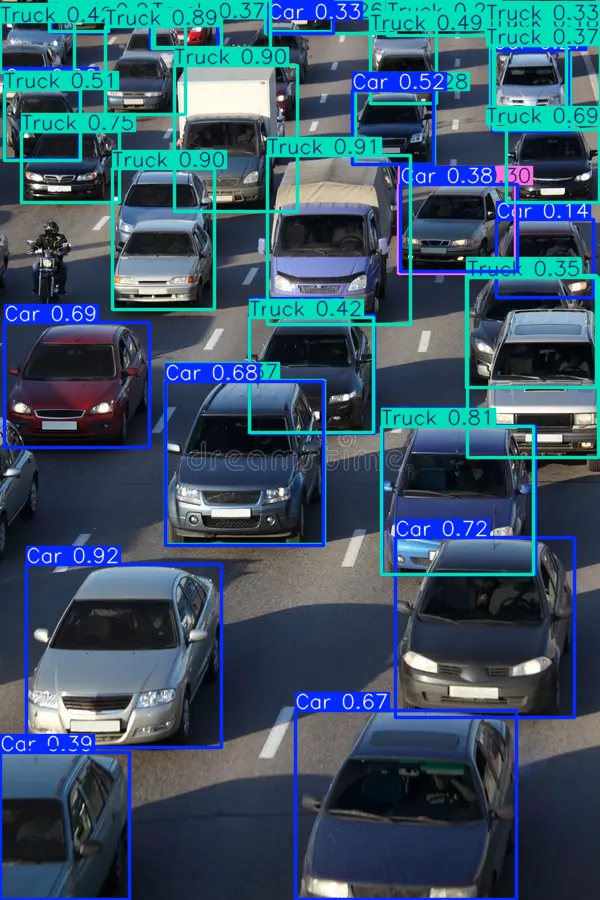

In [67]:
from PIL import Image as PILImage
from IPython.display import display

test_image = DATASET_DIR / "street-traffic.webp"

# Run prediction
results = best_model.predict(
    source=str(test_image),
    conf=0.10,
    imgsz=640,
    save=True
)

# Get the image with bounding boxes and labels
annotated_image = results[0].plot()

# Convert from OpenCV format (BGR) to RGB
annotated_image = annotated_image[:, :, ::-1]

# Display the result
display(PILImage.fromarray(annotated_image))

In [65]:
# Count detections by class
class_ids = results[0].boxes.cls.cpu().numpy().astype(int)
counts = Counter(best_model.names[class_id] for class_id in class_ids)

# Display the counts
print("Detected objects:")
for class_name, count in sorted(counts.items()):
    print(f"{class_name}: {count}")

print(f"\nTotal detections: {sum(counts.values())}")

Detected objects:
Car: 12
Minivan: 1
Truck: 20

Total detections: 33



--- Validation Plots ---
confusion_matrix.png


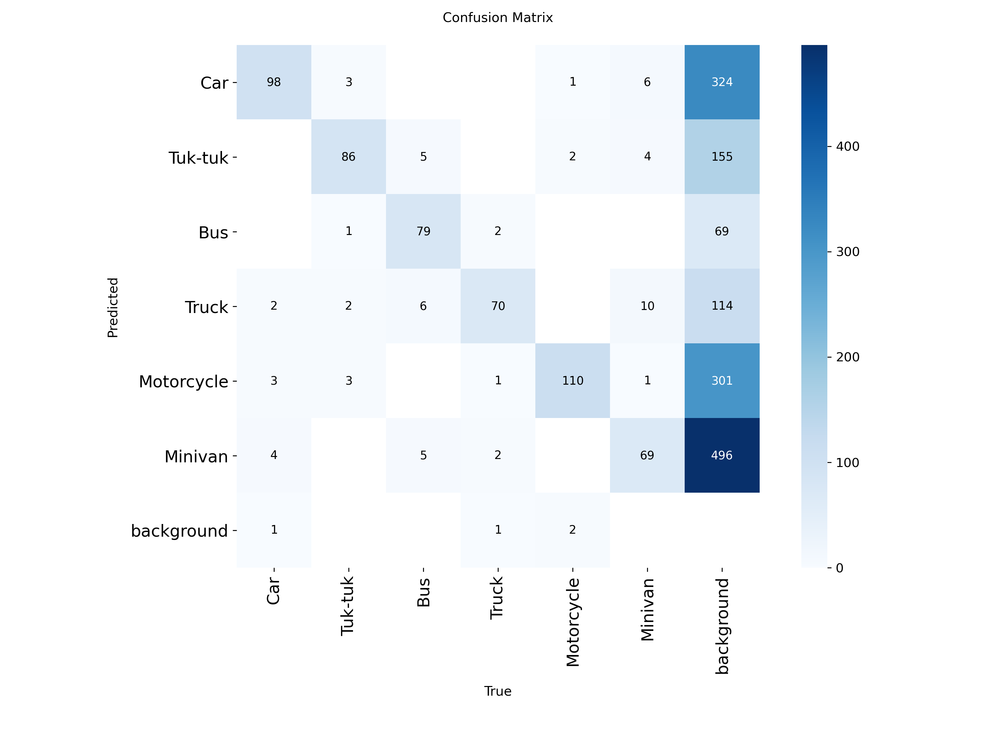


--- Test Plots ---
confusion_matrix.png


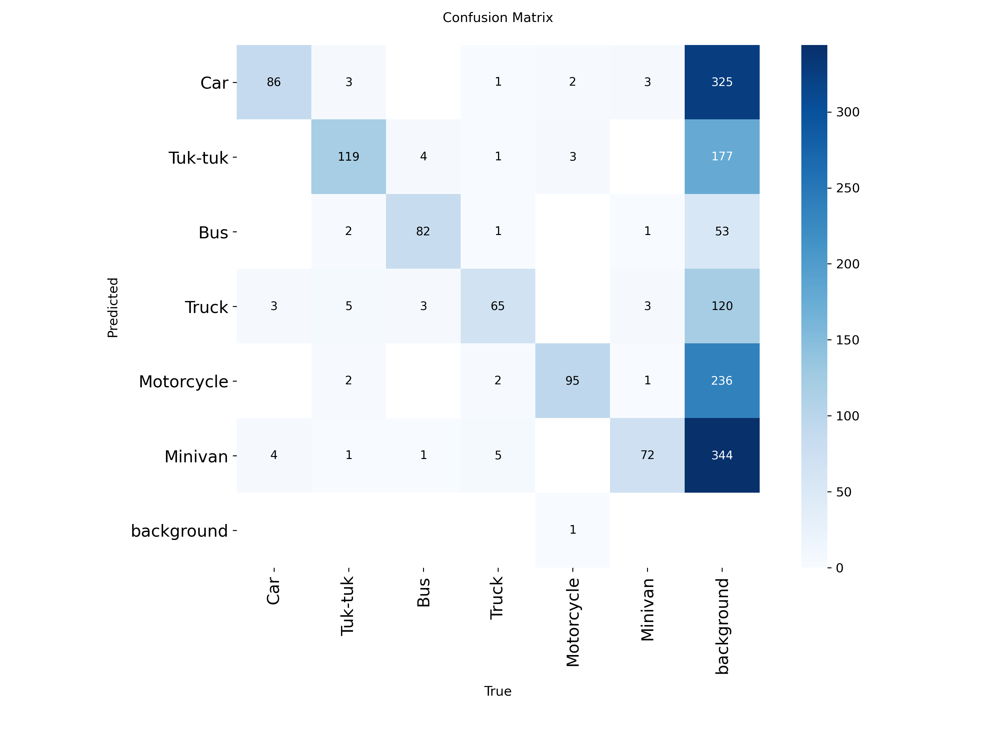

In [48]:
from pathlib import Path
from IPython.display import Image, display

for name, results in [
    ("Validation", val_results),
    ("Test", test_results)
]:
    results_dir = Path(results.save_dir)

    print(f"\n--- {name} Plots ---")

    for filename in [
        "confusion_matrix.png",
        "PR_curve.png",
        "F1_curve.png",
        "P_curve.png",
        "R_curve.png"
    ]:
        plot_path = results_dir / filename

        if plot_path.exists():
            print(filename)
            display(Image(filename=str(plot_path)))

# Saving model to hugging face

In [52]:
import huggingface_hub
print(huggingface_hub.__version__)

1.33.0


In [53]:
from huggingface_hub import notebook_login

notebook_login()

In [54]:
from huggingface_hub import HfApi
from pathlib import Path
import json

# Your Hugging Face repository
repo_id = "Yosriii/vehicle-detection-yolo26n"

# Find your trained model
best_path = Path(train_results.save_dir) / "weights" / "best.pt"

if not best_path.exists():
    raise FileNotFoundError(
        f"Model not found at: {best_path}\n"
        "Check your training output directory."
    )

api = HfApi()

# Create a private model repository
api.create_repo(
    repo_id=repo_id,
    repo_type="model",
    private=True,
    exist_ok=True
)

# Collect evaluation metrics
metrics = {
    "model": "YOLO26n",
    "validation": {
        "precision": float(val_results.box.mp),
        "recall": float(val_results.box.mr),
        "mAP50": float(val_results.box.map50),
        "mAP50_95": float(val_results.box.map)
    },
    "test": {
        "precision": float(test_results.box.mp),
        "recall": float(test_results.box.mr),
        "mAP50": float(test_results.box.map50),
        "mAP50_95": float(test_results.box.map)
    }
}

# Save metrics locally
metrics_path = Path("evaluation_metrics.json")
metrics_path.write_text(
    json.dumps(metrics, indent=4),
    encoding="utf-8"
)

# Upload trained weights
api.upload_file(
    path_or_fileobj=str(best_path),
    path_in_repo="best.pt",
    repo_id=repo_id,
    repo_type="model"
)

# Upload evaluation metrics
api.upload_file(
    path_or_fileobj=str(metrics_path),
    path_in_repo="evaluation_metrics.json",
    repo_id=repo_id,
    repo_type="model"
)

# Upload training history
results_csv = Path(train_results.save_dir) / "results.csv"

if results_csv.exists():
    api.upload_file(
        path_or_fileobj=str(results_csv),
        path_in_repo="results.csv",
        repo_id=repo_id,
        repo_type="model"
    )

print("Upload completed!")
print(f"Model: https://huggingface.co/{repo_id}")

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...ect/train/weights/best.pt:  10%|9         |  541kB / 5.43MB            

Validating                    :           |   0%            

Upload completed!
Model: https://huggingface.co/Yosriii/vehicle-detection-yolo26n
